In [1]:
import sys
from pathlib import Path

racine = Path.cwd().parent
sys.path.insert(0, str(racine))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from fonctions.parametres_swm import ParametresSWM
from fonctions.parametres_numeriques import Paramnum
from fonctions.hamiltonien import energies_seules
from fonctions.fermi_energy import energie_fermi
from fonctions.tracer_bandes import tracer_structure_bandes

In [3]:
# objets
para_swm = ParametresSWM()
para_num = Paramnum(Nq=401)

In [4]:

valeurs_B = np.linspace(0, 3, para_num.N_B)
valeurs_q = np.linspace(-0.5, 0.5, para_num.Nq)
#print(valeurs_B)

In [5]:
# le nombre de bandes
def nombre_branches(n):
    if n == 0:
        return 1
    elif n == 1:
        return 3
    else:
        return 4

In [6]:
### On cree un dictionnaire E
#Ce dictionniaire contient des matrices pour chaque (n,lambda) de taille (N_B,Nq)
E1 = {} # E1 pour les transiations n a n-2

for n in range(para_num.n_max+1):
    for lambda1 in range(nombre_branches(n)):
        E1[n, lambda1] = np.zeros((para_num.N_B, para_num.Nq))


In [7]:
#On remplie chauqe matrice (cle : n,lambda) termes par termes 
#par les valeurs propes correspondant apres diagonlisation

for i, B in enumerate(valeurs_B):
    for j, q in enumerate(valeurs_q):
        for n in range(para_num.n_max+1):
            energies = energies_seules(n, B, q, para_swm)

            for lambda1 in range(len(energies)):
                E1[n, lambda1][i, j] = energies[lambda1]
#print("Dimensions :", E[0, 0].shape)
#print("Première énergie :", E[0, 0][0, 0])
#print("Dernière énergie :", E[0, 0][-1, -1])

In [8]:
## Calcul de EF(B)
#on cree une liste de taille N_B pour calculeerr Ef en fonction de B
from fonctions.fermi_energy import tableaux_energies
EF = np.zeros(para_num.N_B) #liste 

for i, B in enumerate(valeurs_B):
    energies_totales = tableaux_energies(B, para_swm, para_num)

    N = len(energies_totales)

    EF[i] = 0.5*(
        energies_totales[N//2 - 1] +
        energies_totales[N//2]
                )


In [9]:
### On cree un dictinonnaire transitions 
#Cette dictionnniare avec cle (n,lambda 1 ,lambda2) contient des matrices des differnce entre 
#(n,lambda1) et (n-2,lambda2) avec condition sur le niveau de fermi.

transitions = {} # les nombbres des elements (matrices) dans cette dictionnaire egale nombres des transitions totales.

for n in range(2, para_num.n_max+1): # n commence par 2 car je prend les transitions n et n-2
    for lambd1 in range(nombre_branches(n)):
        for lambd2 in range(nombre_branches(n - 2)):

            E_initial = E1[n , lambd1]
            E_final = E1[n-2, lambd2]

            difference = E_final - E_initial

            condition = (
                (E_initial < EF[:, None]) &
                (E_final > EF[:, None])
            )

            transitions[n, lambd1, lambd2] = np.where(
                condition, difference, 0 # fonction qui met le valeur de differnce si condition est vrai , 0 sinon
            )

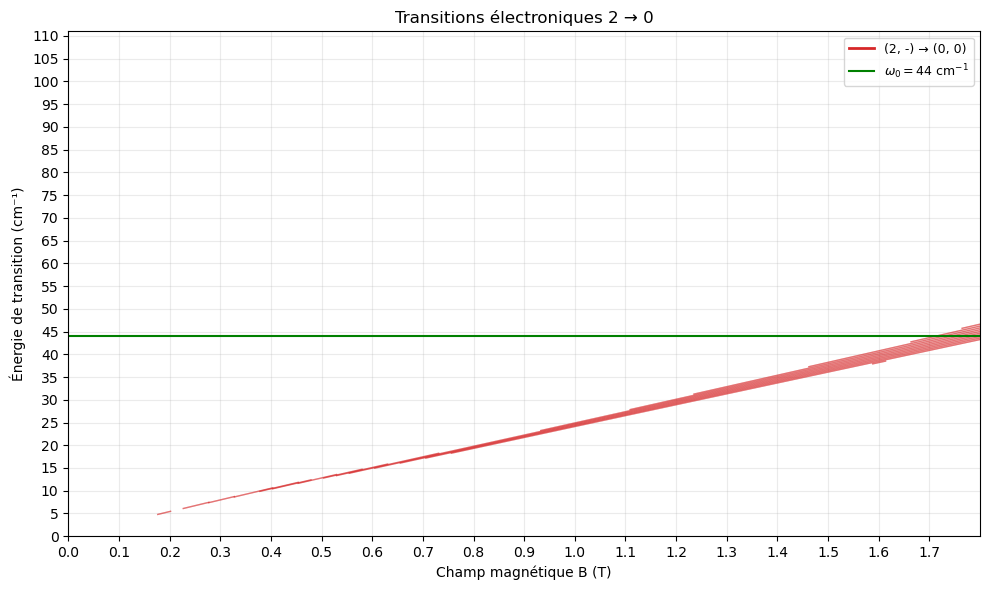

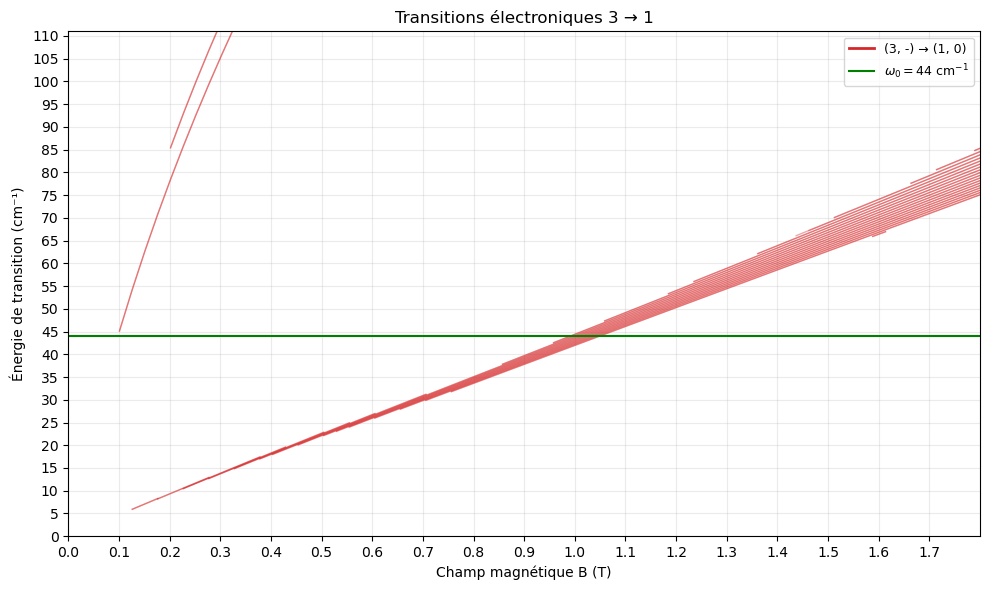

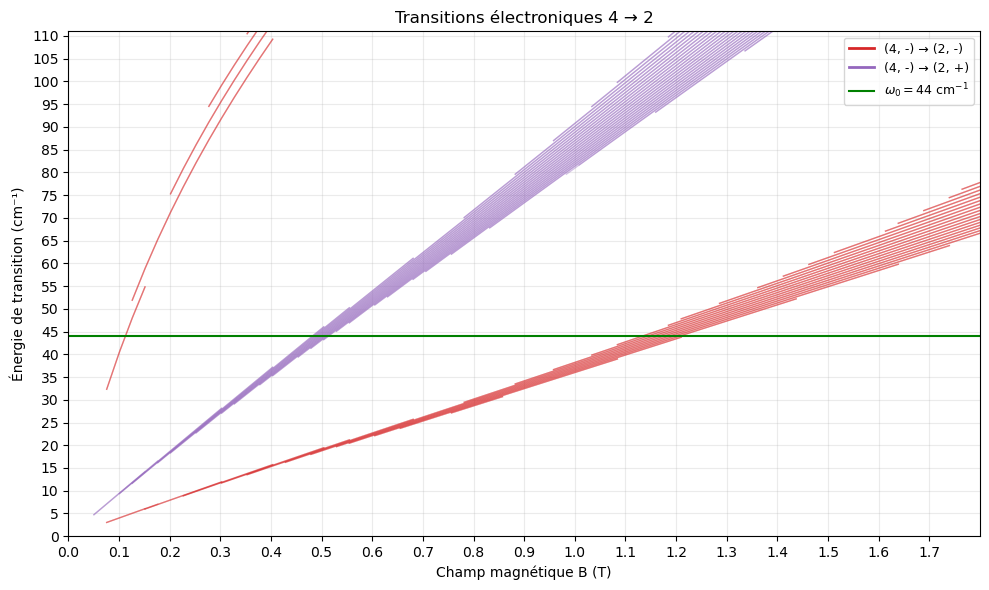

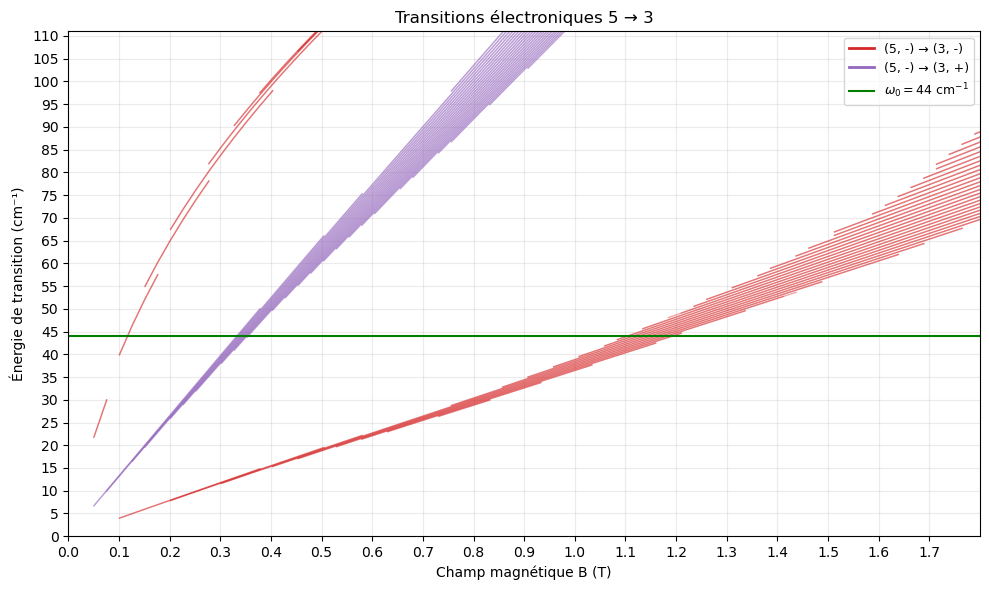

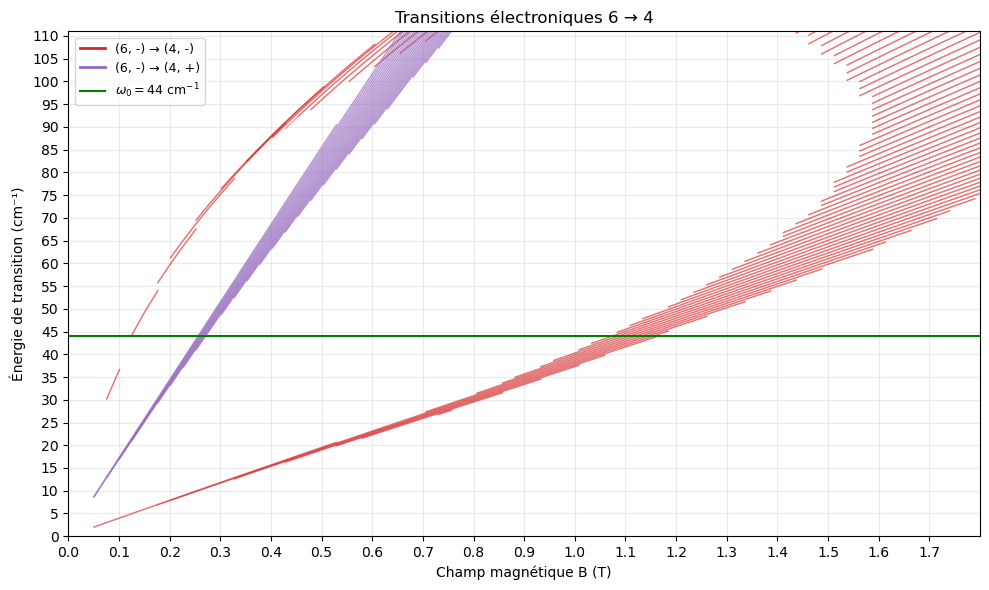

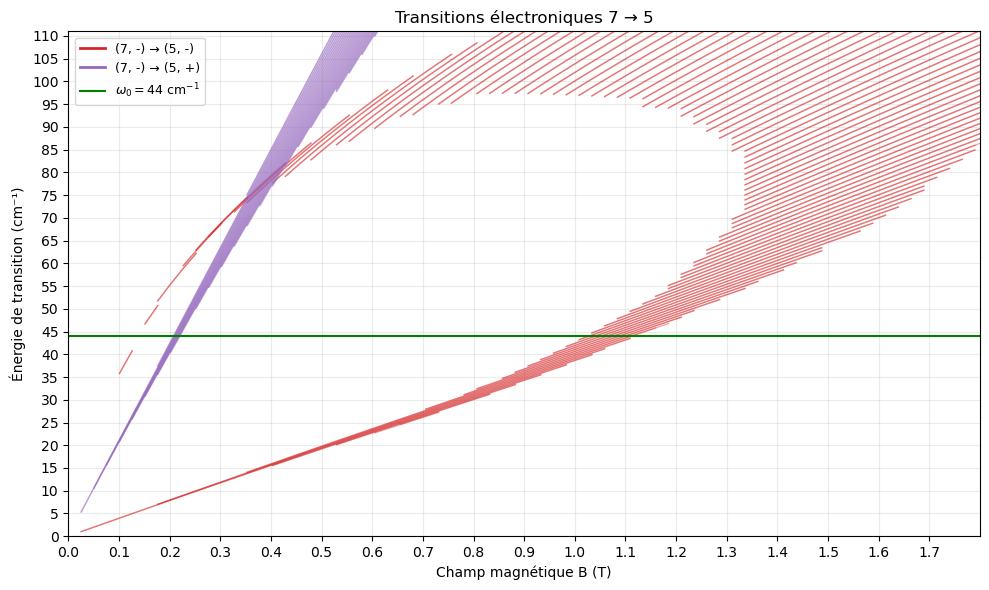

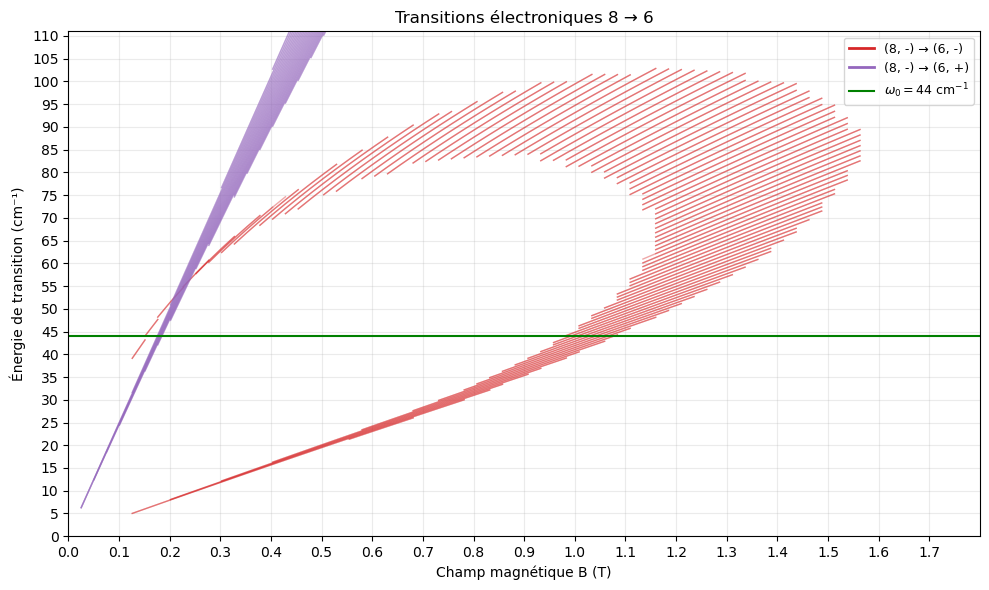

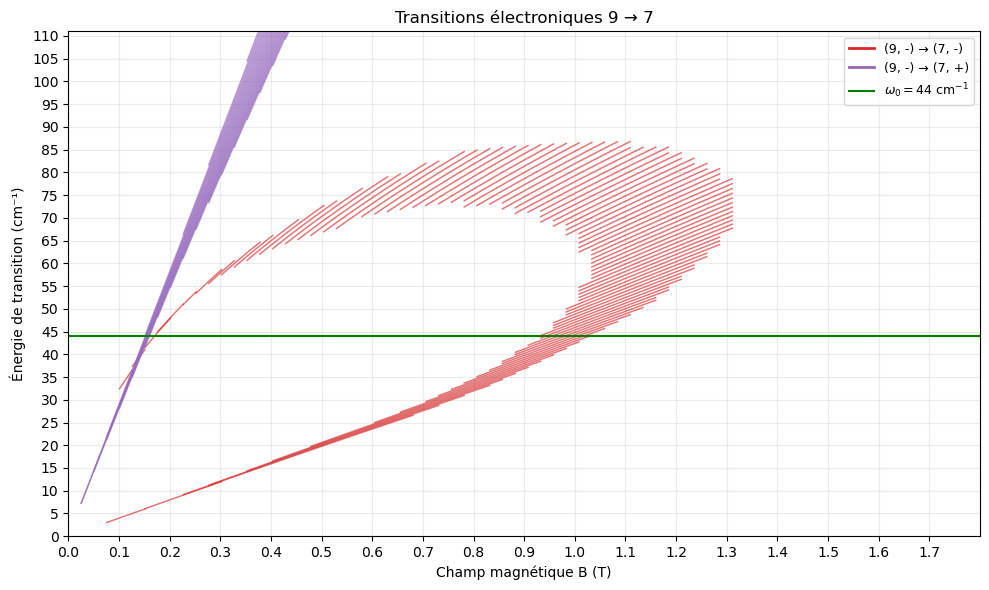

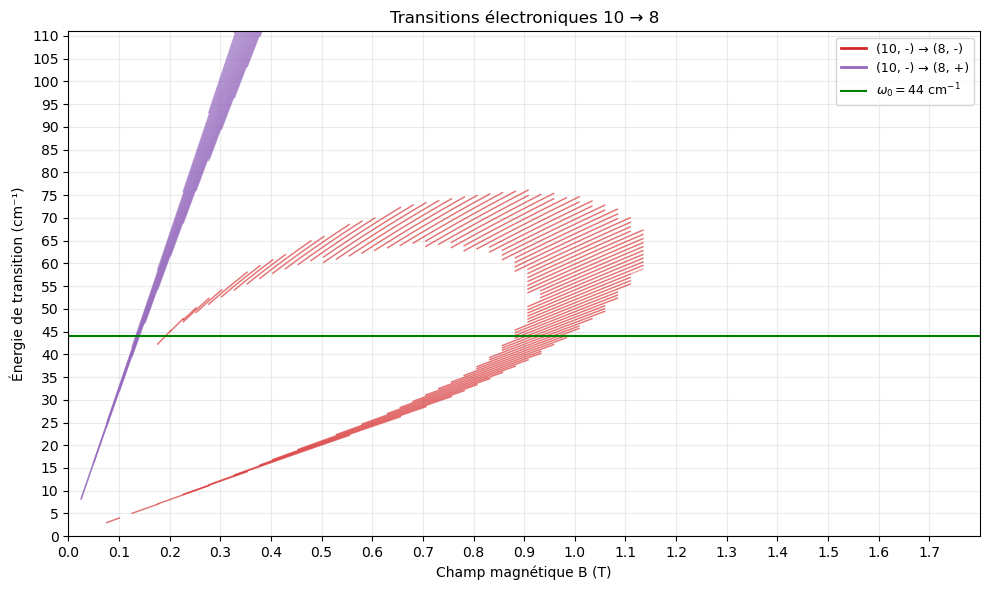

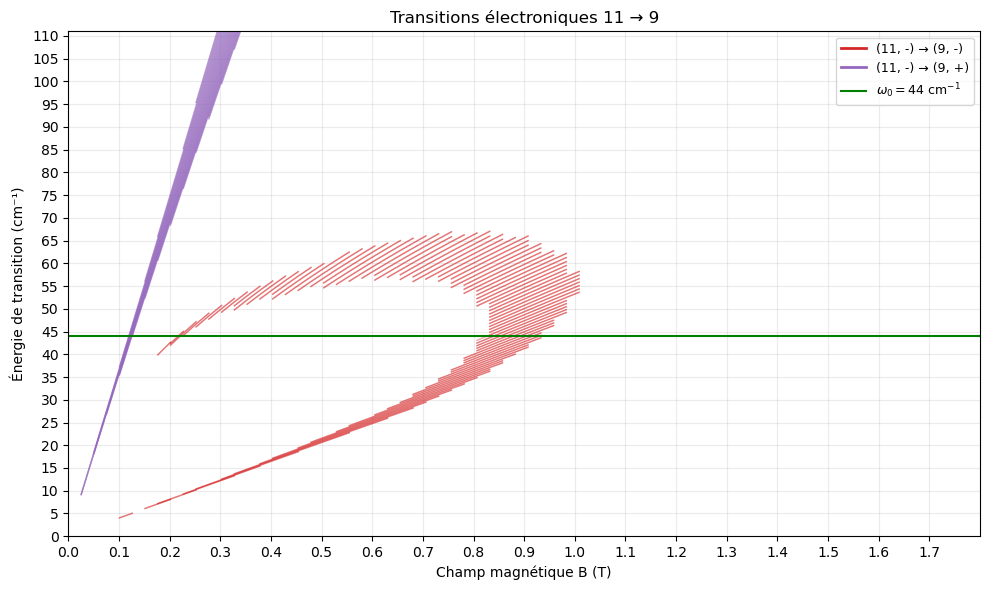

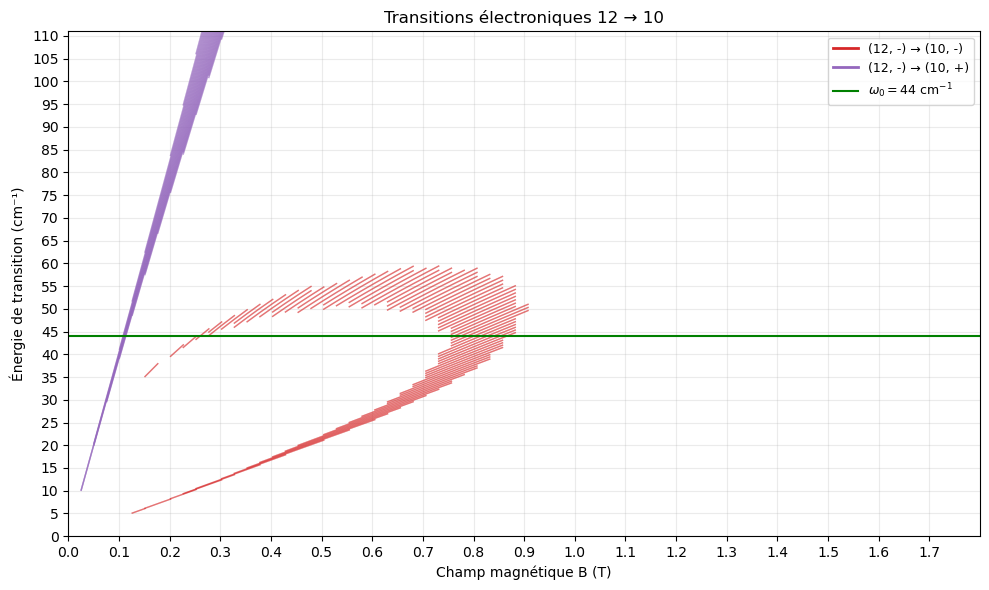

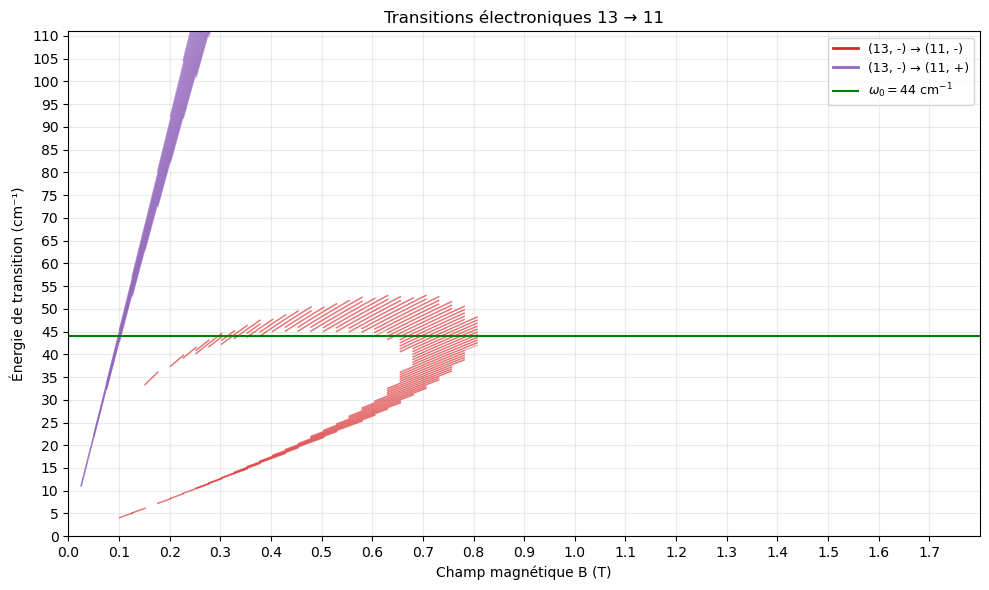

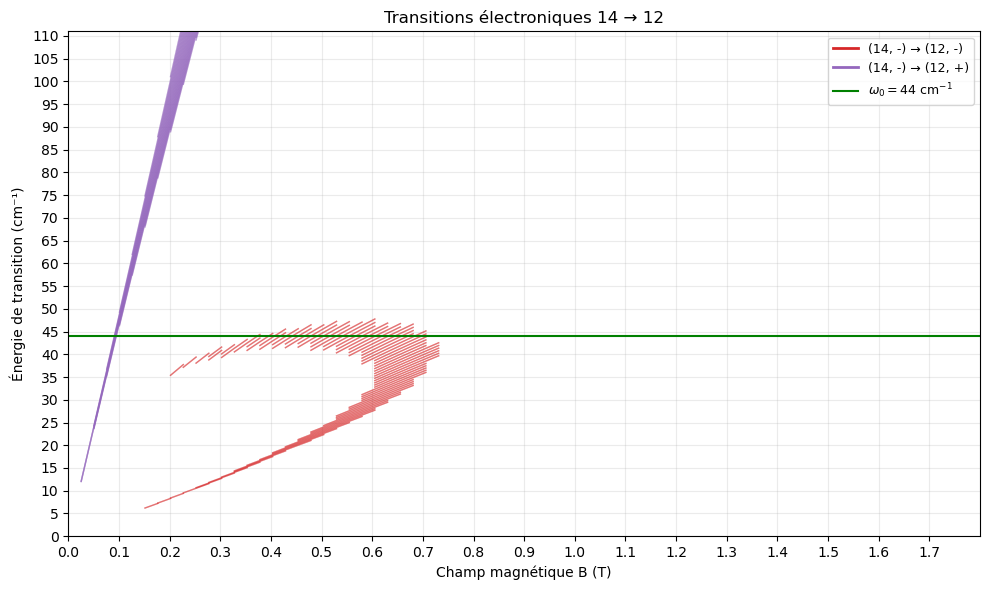

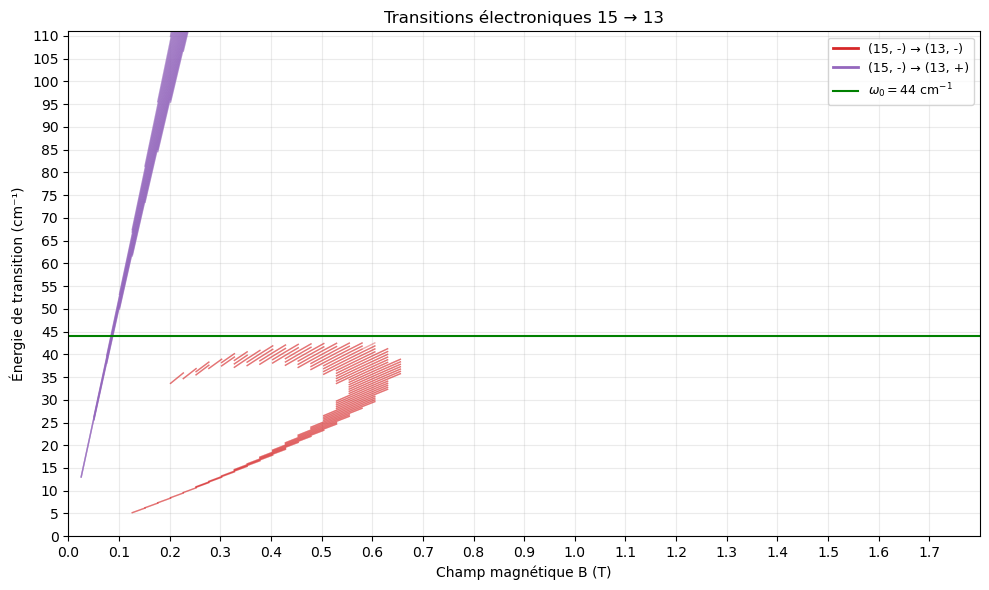

In [21]:

from fonctions.unites_phy import Unites_phy
unites_phy=Unites_phy()

noms_branches = {
    0: ["0"],                  # Pour n = 0 : une seule branche
    1: ["--", "0", "++"],      # Pour n = 1 : trois branches
}

# Pour n >= 2, il y a quatre branches
for n in range(2, para_num.n_max+1):
    noms_branches[n] = ["--", "-", "+", "++"]


for n in range(2, para_num.n_max+1):

    # Créer une nouvelle figure pour chaque valeur de n
    plt.figure(figsize=(10, 6))

    # Nombre total de transitions possibles entre les branches pour n donnes
    nombre_transitions = (
        nombre_branches(n) * nombre_branches(n - 2)
    )

    # Attribuer une couleur à chaque transition
    couleurs = plt.cm.tab10(
        np.linspace(0, 1, nombre_transitions)
    )

    # Indice de la couleur utilisée pour chaque transition
    indice_couleur = 0

    # Parcourir les branches initiales d'indice n
    for lambd1 in range(nombre_branches(n)):

        # Parcourir les branches finales d'indice n-2
        for lambd2 in range(nombre_branches(n - 2)):

            
            matrice = transitions[n, lambd1, lambd2] # martrice pour chaque transitions contient deja les energies calcules

            # Couleur  pour cette transition
            couleur = couleurs[indice_couleur]

            # Indique si au moins une partie de la transition
            # sera visible sur le graphique
            transition_visible = False

            # Parcourir toutes les valeurs de q
            for j in range(len(valeurs_q)):

                # Convertir les énergies de eV en cm⁻¹
                energie_cm = matrice[:, j]*unites_phy.eV_to_cm1

                
                energie_cm = np.where(
                    (matrice[:, j] > 0) &
                    (energie_cm > 0) &
                    (energie_cm <= 250),
                    energie_cm,
                    np.nan
                )

                # Verifier qu'il reste au moins une energie valide
                if np.any(np.isfinite(energie_cm)):
                    transition_visible = True

                    # Tracer l'energie en fonction du champ magnétique B
                    plt.plot(
                        valeurs_B,
                        energie_cm,
                        color=couleur,
                        alpha=0.4,
                        linewidth=1
                    )

            #legende si visible
            if transition_visible:

                # Construire le nom de la transition
                etiquette = (
                    f"({n}, {noms_branches[n][lambd1]}) "
                    f"→ ({n-2}, {noms_branches[n-2][lambd2]})"
                )

                # Créer une entrée dans la légende
                # sans ajouter de courbe supplémentaire visible
                plt.plot(
                    [],
                    [],
                    color=couleur,
                    linewidth=2,
                    label=etiquette
                )

            # Passer à la couleur de la transition suivante
            indice_couleur += 1

    plt.axhline(y=44, color="green", linestyle="-", linewidth=1.5,
            label=r"$\omega_0 = 44\ \mathrm{cm}^{-1}$")
    plt.xlabel("Champ magnétique B (T)")
    plt.ylabel("Énergie de transition (cm⁻¹)")
    plt.xlim(0, 1.8)
    plt.xticks(np.arange(0,1.8 , 0.1))
    plt.ylim(0, 111)
    plt.yticks(np.arange(0, 111, 5))
    plt.title(f"Transitions électroniques {n} → {n-2}")
    plt.grid(True, alpha=0.25)
    plt.legend(fontsize=9, loc="best")
    plt.tight_layout()
    plt.show()


In [16]:
# Pour les transitions n a n+2
### On cree un dictionnaire E
#Ce dictionniaire contient des matrices pour chaque (n,lambda) de taille (N_B,Nq)
E2 = {} # E2 pour les transiations n a n+2

for n in range(para_num.n_max+1):
    for lambda1 in range(nombre_branches(n)):
        E2[n, lambda1] = np.zeros((para_num.N_B, para_num.Nq))


In [17]:
#On remplie chauqe matrice (cle : n,lambda) termes par termes 
#par les valeurs propes correspondant apres diagonlisation

for i, B in enumerate(valeurs_B):
    for j, q in enumerate(valeurs_q):
        for n in range(para_num.n_max+1):
            energies = energies_seules(n, B, q, para_swm)

            for lambda1 in range(len(energies)):
                E2[n, lambda1][i, j] = energies[lambda1]
#print("Dimensions :", E[0, 0].shape)
#print("Première énergie :", E[0, 0][0, 0])
#print("Dernière énergie :", E[0, 0][-1, -1])

In [18]:
### On cree un dictinonnaire transitions 
#Cette dictionnniare avec cle (n,lambda 1 ,lambda2) contient des matrices des differnce entre 
#(n,lambda1) et (n+2,lambda2) avec condition sur le niveau de fermi.

transitions2 = {} # les nombbres des elements (matrices) dans cette dictionnaire egale nombres des transitions totales.

for n in range(0, para_num.n_max-1): # n commence par 0 car je prend les transitions n et n+2
    for lambd1 in range(nombre_branches(n)):
        for lambd2 in range(nombre_branches(n + 2)):

            E_initial = E2[n , lambd1]
            E_final = E2[n+2, lambd2]

            difference = E_final - E_initial

            condition = (
                (E_initial < EF[:, None]) &
                (E_final > EF[:, None])
            )

            transitions2[n, lambd1, lambd2] = np.where(
                condition, difference, 0 
            )# fonction qui met le valeur de differnce si condition est vrai , 0 sinon

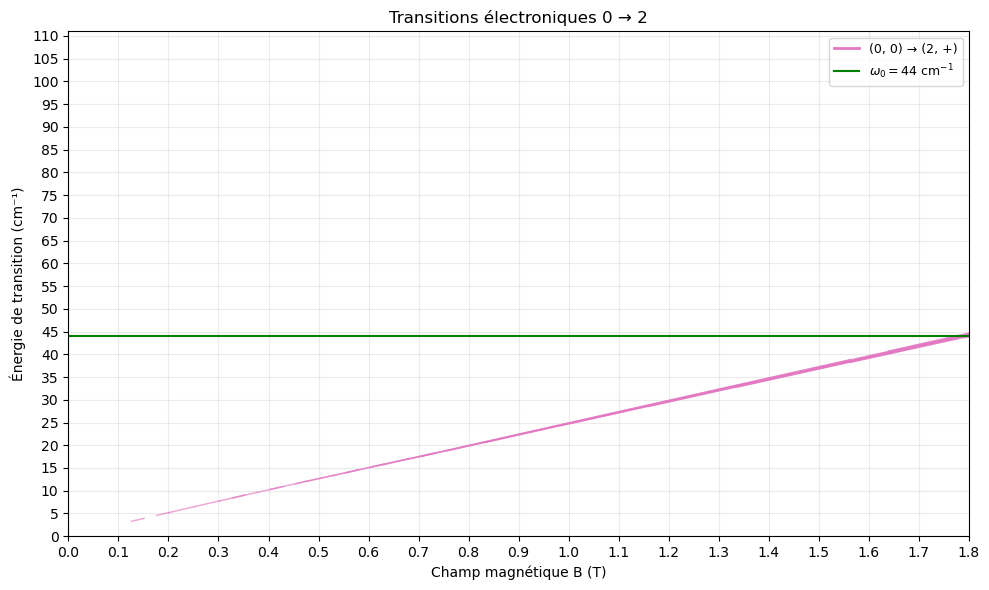

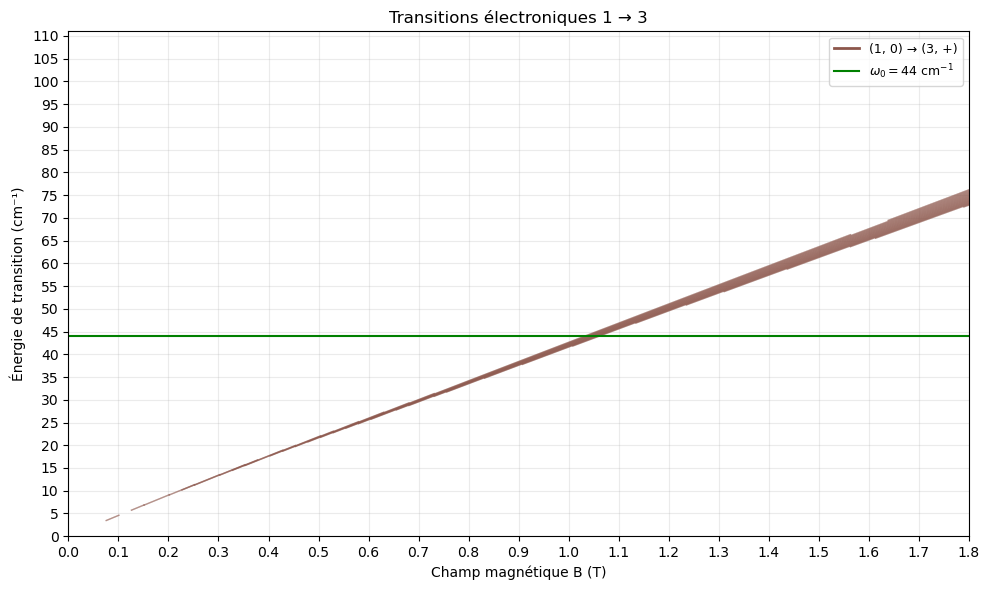

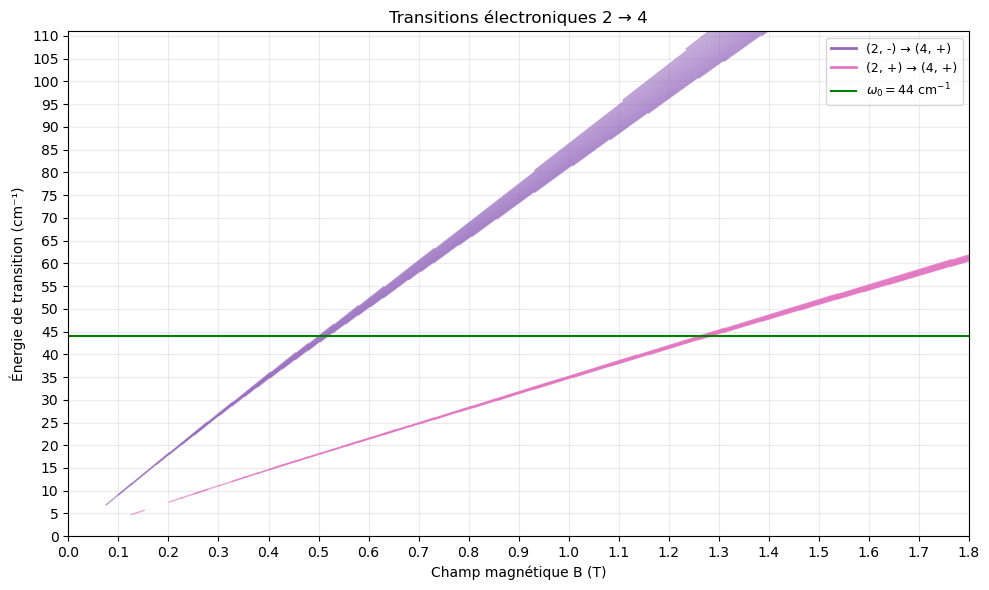

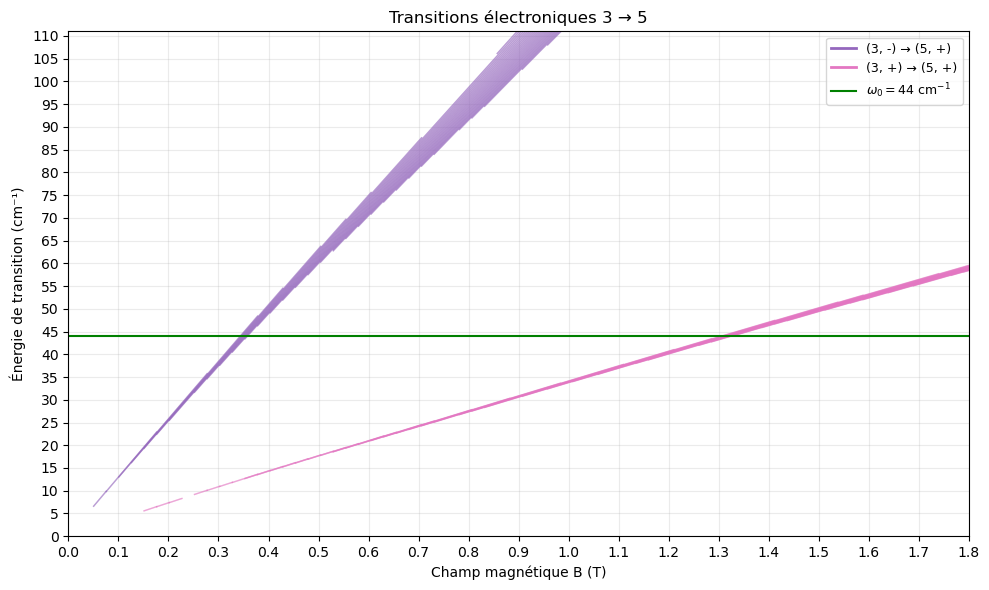

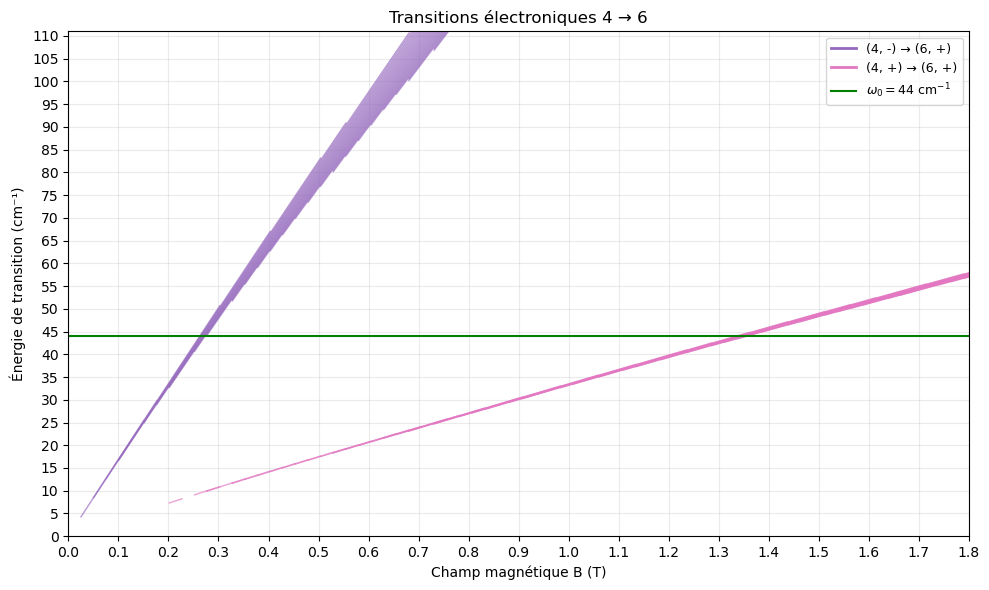

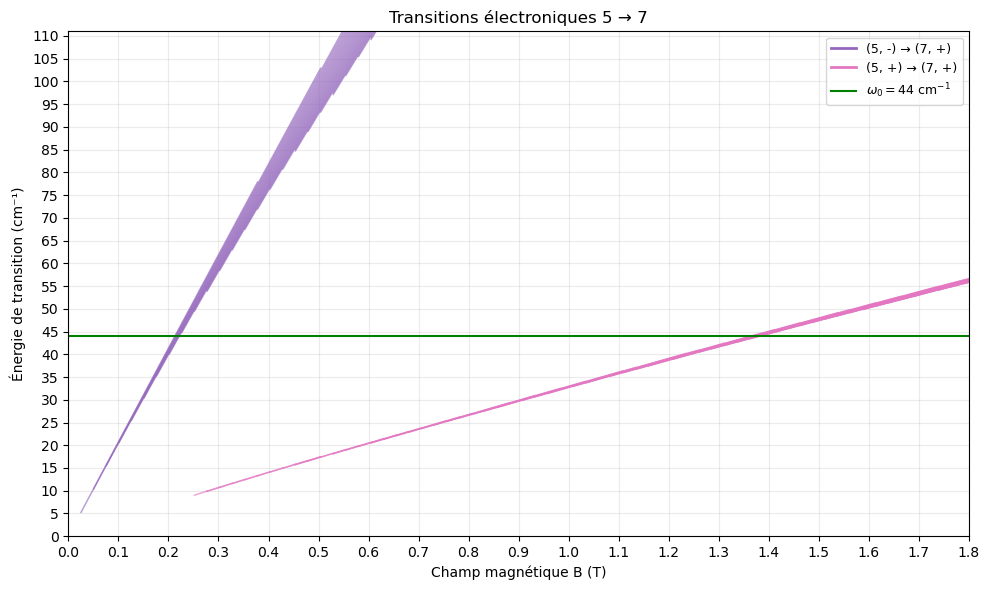

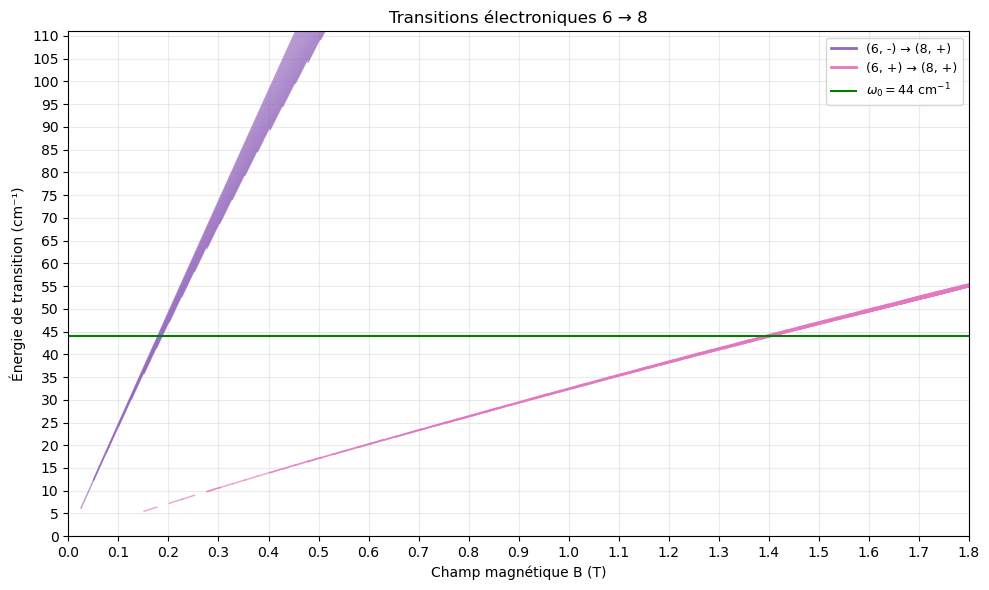

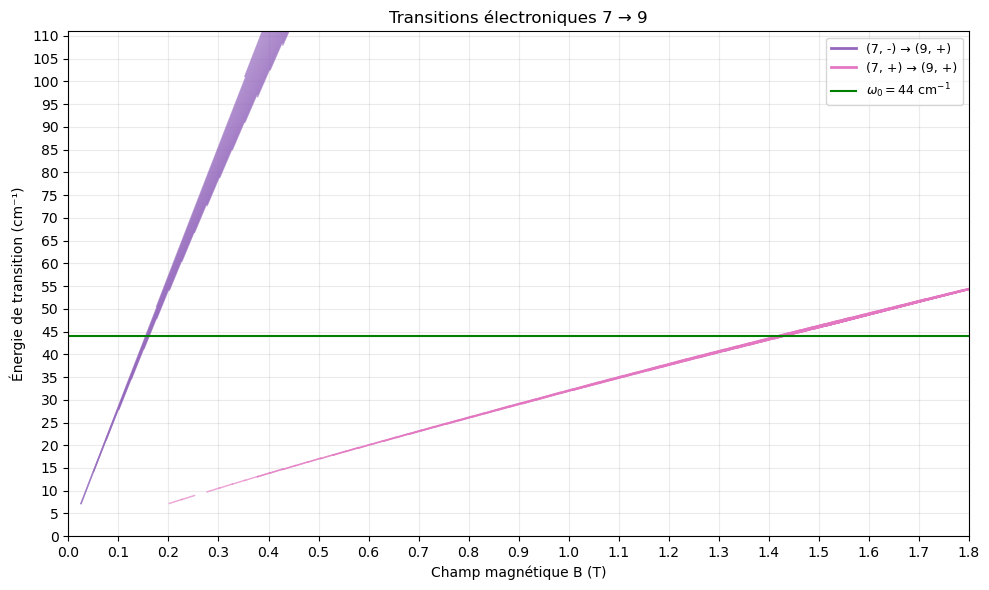

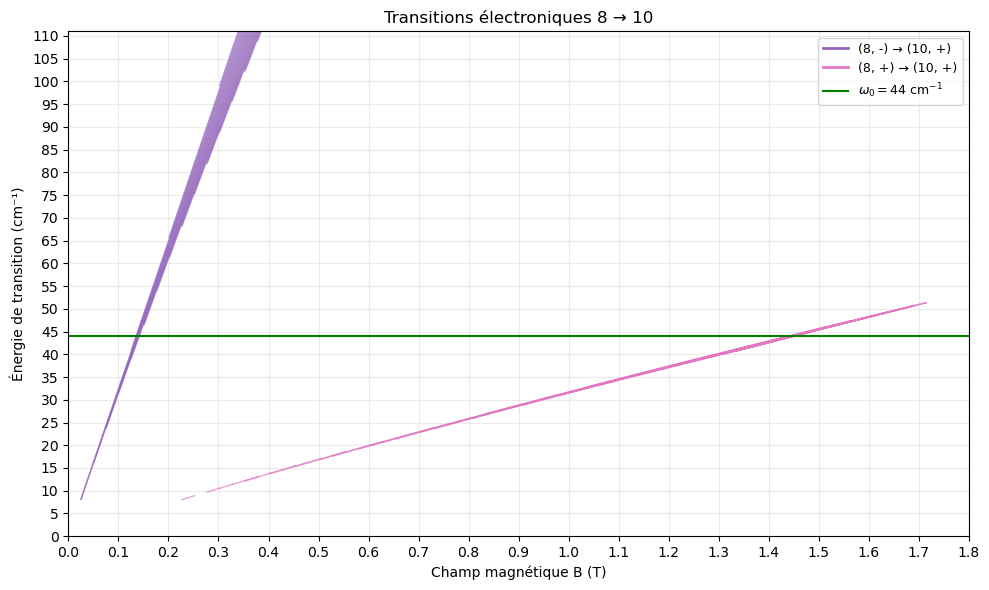

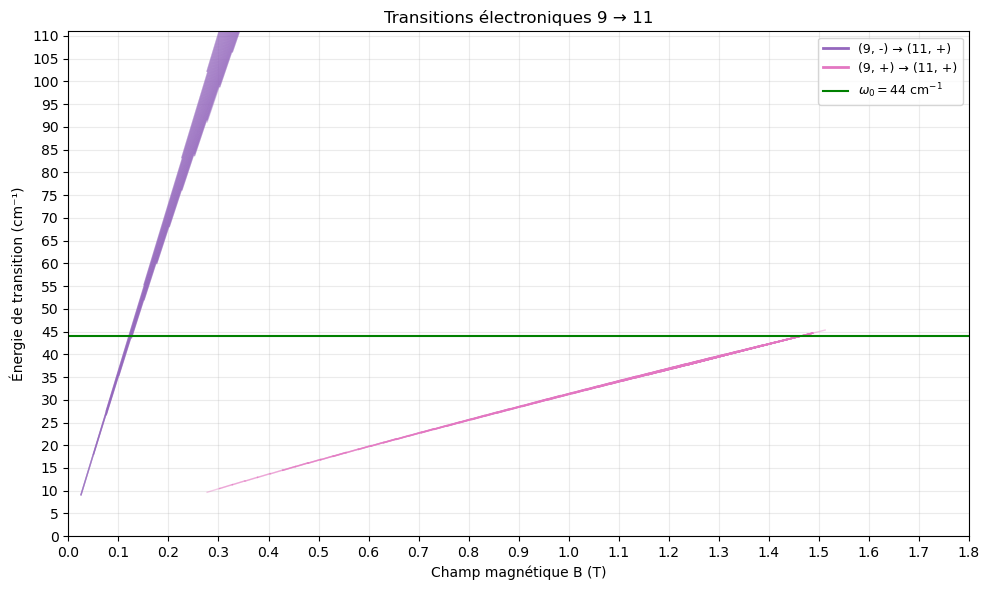

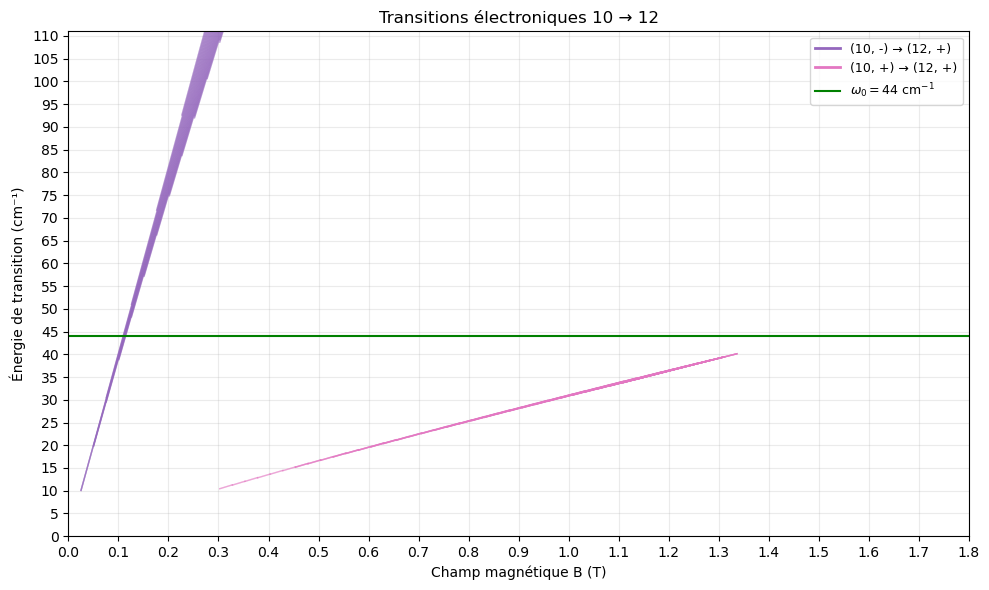

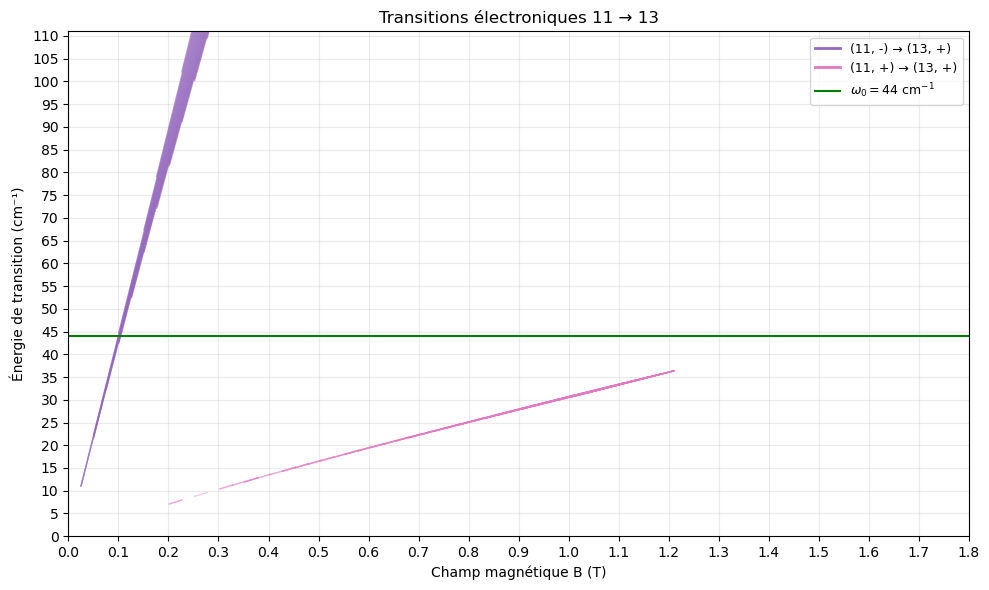

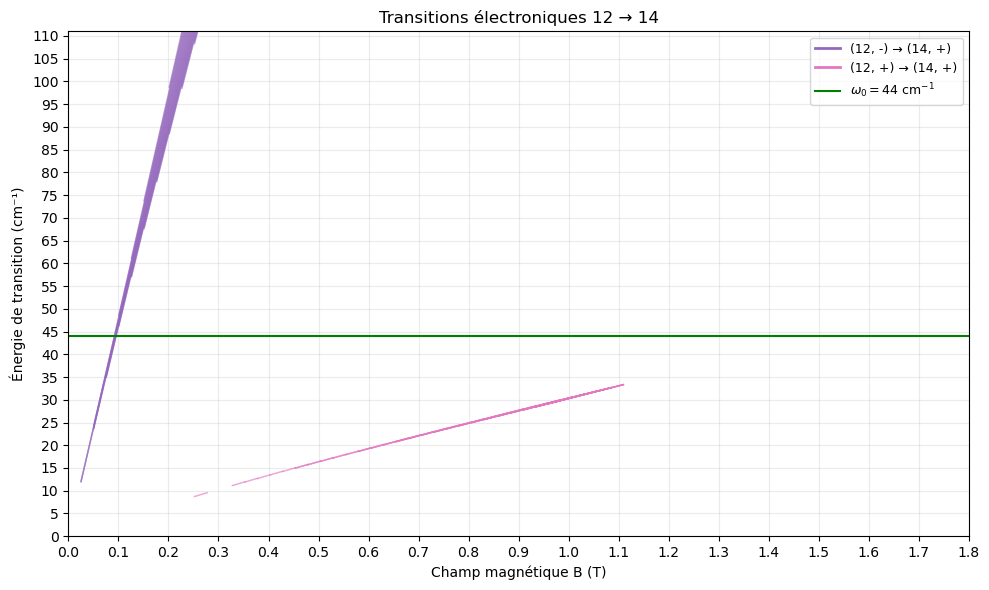

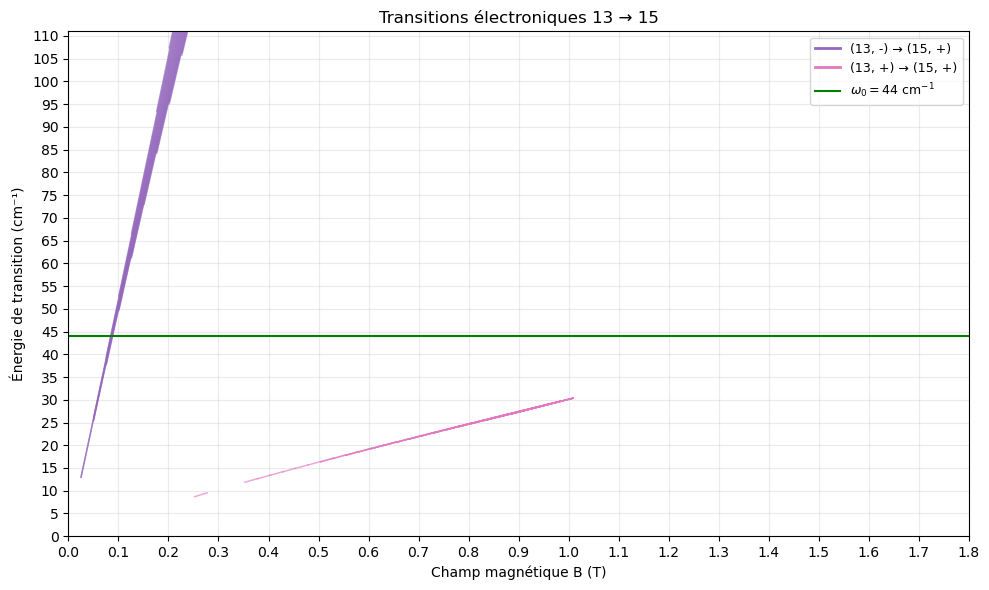

In [19]:
noms_branches = {
    0: ["0"],
    1: ["--", "0", "++"],
}

# Pour n >= 2
for n in range(2, para_num.n_max + 1):
    noms_branches[n] = ["--", "-", "+", "++"]


# Transitions n -> n+2
for n in range(0, para_num.n_max - 1):

    plt.figure(figsize=(10, 6))

    nombre_transitions = (
        nombre_branches(n) * nombre_branches(n + 2)
    )

    couleurs = plt.cm.tab10(
        np.linspace(0, 1, nombre_transitions)
    )

    indice_couleur = 0

    for lambd1 in range(nombre_branches(n)):
        for lambd2 in range(nombre_branches(n + 2)):

            matrice = transitions2[n, lambd1, lambd2] # attention transitions2
            couleur = couleurs[indice_couleur]
            transition_visible = False

            for j in range(len(valeurs_q)):

                energie_cm = matrice[:, j] *unites_phy.eV_to_cm1

                energie_cm = np.where(
                    (matrice[:, j] > 0) &
                    (energie_cm > 0) &
                    (energie_cm <= 250),
                    energie_cm,
                    np.nan
                )

                if np.any(np.isfinite(energie_cm)):
                    transition_visible = True

                    plt.plot(
                        valeurs_B,
                        energie_cm,
                        color=couleur,
                        alpha=0.4,
                        linewidth=1
                    )

            if transition_visible:
                etiquette = (
                    f"({n}, {noms_branches[n][lambd1]}) "
                    f"→ ({n+2}, {noms_branches[n+2][lambd2]})"
                )

                plt.plot(
                    [],
                    [],
                    color=couleur,
                    linewidth=2,
                    label=etiquette
                )

            indice_couleur += 1

    plt.axhline(
        y=44,
        color="green",
        linestyle="-",
        linewidth=1.5,
        label=r"$\omega_0 = 44\ \mathrm{cm}^{-1}$"
    )

    plt.xlabel("Champ magnétique B (T)")
    plt.ylabel("Énergie de transition (cm⁻¹)")
    plt.xlim(0, 1.8)
    plt.xticks(np.arange(0, 1.81, 0.1))
    plt.ylim(0, 111)
    plt.yticks(np.arange(0, 112, 5))
    plt.title(f"Transitions électroniques {n} → {n+2}")
    plt.grid(True, alpha=0.25)
    plt.legend(fontsize=9, loc="best")
    plt.tight_layout()
    plt.show()


-0.015141595691941762


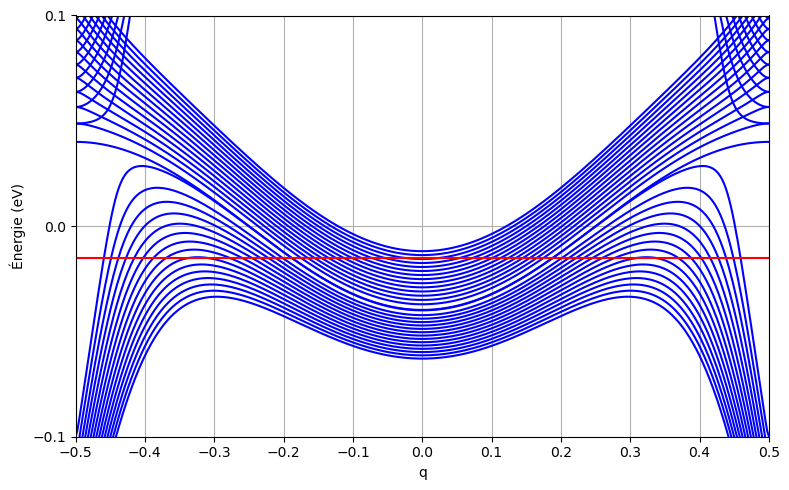

In [20]:
ef=energie_fermi(B=1,para_swm=para_swm,para_num=para_num)
print(ef)
tracer_structure_bandes(B=1,para_num=para_num,para_swm=para_swm,xlim= (-0.5,0.5),ylim=(-0.1,0.1),Ef=ef)